# Сверточная сеть
В этом ноутбуке мы расширим предыдущий и создадим первую сверточную сеть

In [1]:
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import datasets
from torchvision.transforms import ToTensor
from matplotlib import pyplot as plt

In [2]:
import os
import pandas as pd
from torchvision.io import read_image


# Создание датасета

Загрузим FashionMNIST (https://github.com/zalandoresearch/fashion-mnist)


In [3]:
train_data = datasets.FashionMNIST(
    root="data",
    train=True,
    download=True,
    transform=ToTensor(),
)

# Download test data from open datasets.
test_data = datasets.FashionMNIST(
    root="data",
    train=False,
    download=True,
    transform=ToTensor(),
)

In [4]:
labels_map = {
    0: "T-Shirt",
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "Ankle Boot",
}

In [5]:
def plot_samples(data, labels_map, cols=3, rows=3):
    figure = plt.figure(figsize=(8, 8))
    for i in range(1, cols * rows + 1):
        sample_idx = torch.randint(len(data), size=(1,)).item()
        img, label = data[sample_idx]
        figure.add_subplot(rows, cols, i)
        if type(label) == torch.Tensor:
            plt.title(labels_map[label.item()])
        else:
            plt.title(labels_map[label])
        plt.axis("off")
        plt.imshow(img.squeeze(), cmap="gray")
    plt.show()

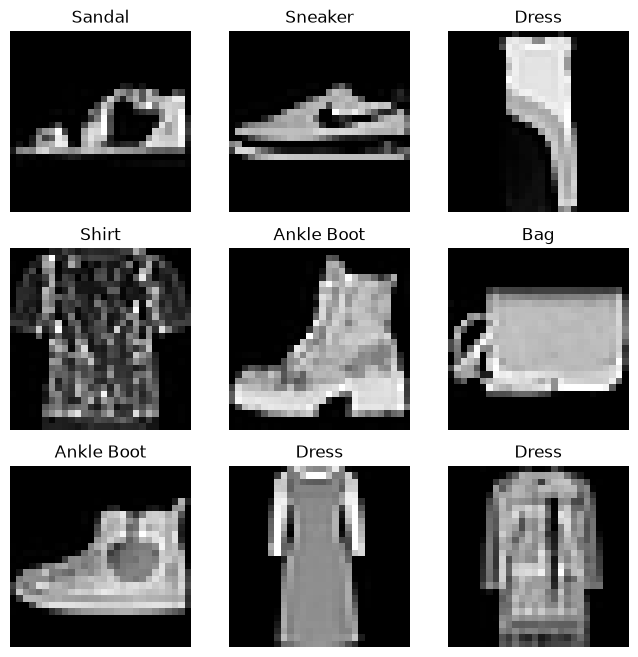

In [6]:
plot_samples(train_data, labels_map, cols=3, rows=3)

In [7]:
train_dataloader = DataLoader(train_data, batch_size=64, shuffle=True)
test_dataloader = DataLoader(test_data, batch_size=64, shuffle=True)

Feature batch shape: torch.Size([64, 1, 28, 28])
Labels batch shape: torch.Size([64])


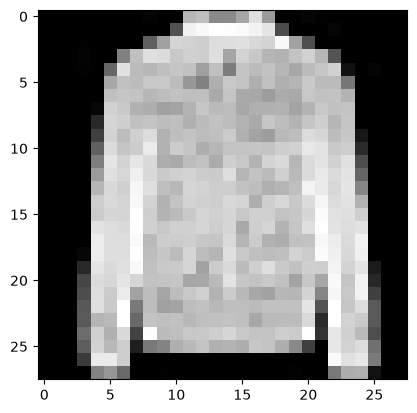

Label: 4


In [ ]:
train_features, train_labels = next(iter(train_dataloader))
print(f"Feature batch shape: {train_features.size()}")
print(f"Labels batch shape: {train_labels.size()}")
img = train_features[0].squeeze().reshape(28,28)
label = train_labels[0]
plt.imshow(img, cmap="gray")
plt.show()
print(f"Label: {label}")

In [9]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using {device} device")


Using cpu device


Теперь создадим класс модели и интстанциируем её. В данном случае это простая сверточная сеть: изображение проходит через блоки из сверток `nn.Conv2d` с batch-нормализацией (`nn.BatchNorm2d`) и активацией (`nn.ReLU`), а затем карта признаков разворачивается в вектор и подается в линейную голову `nn.Linear`, выдающую логиты для 10 классов. Однако модель может быть сколько угодно сложной. Главное, чтобы она наследовала класс `nn.Module`. Более того, можно написать любой слой собственноручно, также отнаследовав этот класс.


### Архитектура модели

Схема ниже показывает названия слоев и размер выхода каждого слоя (для одного изображения):

![diagram](../images/simple_cnn.png)

In [10]:
class NeuralNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.base = nn.Sequential(
            # your code
            nn.Conv2d(1, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(32, 16, 3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU()
        )
        self.head = nn.Linear(16*28*28, 10)

    def forward(self, x):
        x = self.base(x)
        # Необходимо превратить вход в вектор, чтобы можно было применить линейный слой

        x = x.view(x.size(0), -1)
        logits = self.head(x)
        return logits

model = NeuralNetwork().to(device)
print(model)

NeuralNetwork(
  (base): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(32, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU()
  )
  (head): Linear(in_features=12544, out_features=10, bias=True)
)


Часто вместо решейпа перед головой используют пулинг. Это специальный слой, который накладывается на вход и позволяет получить его преобразование (max, avg) без весов:
![alt text](..\images\max_pool.png "Stride=1, padding=0")

Если сделать MaxPool2d или AvgPool2d с размером ядра, равным размеру входа, то получится вектор такого же размера, как исходное число каналов. Однако, все равно придется добавить дополнительное измерение.

**Задание**: Измените модель, используя MaxPool или AvgPool вместо view(). Сравните результаты.

In [16]:
class NeuralNetworkPool(nn.Module):
    def __init__(self):
        super().__init__()
        self.base = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(32, 16, 3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
        )
        self.pool = nn.MaxPool2d(kernel_size=28)
        self.head = nn.Sequential(
            nn.Linear(16, 64),
            nn.ReLU(),
            nn.Linear(64, 10),
        )

    def forward(self, x):
        x = self.base(x)            
        x = self.pool(x)           
        x = x.view(x.size(0), -1)  
        return self.head(x)

In [17]:
def evaluate(model, loader):
    model.eval().to(device)
    correct = total = 0
    with torch.no_grad():
        for X, y in loader:
            X, y = X.to(device), y.to(device)
            correct += (model(X).argmax(1) == y).sum().item()
            total += y.size(0)
    return correct / total

def train(model, epochs=3):
    model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    loss_fn = nn.CrossEntropyLoss()
    for _ in range(epochs):
        model.train()
        for X, y in train_dataloader:
            X, y = X.to(device), y.to(device)
            opt.zero_grad()
            loss_fn(model(X), y).backward()
            opt.step()
    return evaluate(model, test_dataloader)

print("view:   ", train(NeuralNetwork()))      
print("pool:   ", train(NeuralNetworkPool()))  

view:    0.9041
pool:    0.7856


Зададим функцию ошибки и оптимизатор. Функция ошибки также наследуется от torch.nn.Module и может быть стандартной, состоять как из нескольких стандартных функций или их модификаций. Большое количество функций ошибки уже реализовано в Pytorch.

Внутри каждой итерации обучения оптимизация происходит в три этапа:
Вызов optimizer.zero_grad() для обнуления градиентов параметров модели. Градиенты по умолчанию складываются; чтобы избежать двойного подсчета, мы явно обнуляем их на каждой итерации.

Получение градиентов для каждого веса с помощью loss.backward().
Как только мы получили наши градиенты, остается вызвать optimizer.step(), чтобы изменить параметры в соответствии с нашим алгоритмом оптимизации. 

In [18]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=1e-3)

Обучим модель. Для этого нужно описать цикл обучения и проверки модели. В наивном случае создается две функции train и validate (test), которые вызываются в цикле по эпохам. В дальнейшем, при усложнении прохода по эпохе, может появиться метод train, целый класс Trainer и т.д. Пока что реализуем наивный вариант.

In [19]:
def train(dataloader, model, loss_fn, optimizer):
    size = len(dataloader.dataset)
    model.train()
    for batch_idx, (inputs, targets) in enumerate(dataloader):
        inputs, targets = inputs.to(device), targets.to(device)

        # Compute prediction error
        preds = model(inputs)
        loss = loss_fn(preds, targets)

        # Backpropagation
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        if batch_idx % 100 == 0:
            loss, current = loss.item(), (batch_idx + 1) * len(inputs)
            print(f"loss: {loss:>7f}  [{current:>5d}/{size:>5d}]")
            
        ''' Чтобы сделать задание со сравнением лоссов, не забудьте 
            реализовать трекинг минимального лосса  '''

In [20]:
def test(dataloader, model, loss_fn, num_classes=10):
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    model.eval()
    test_loss, num_correct = 0, 0
    tp = torch.zeros(num_classes)
    fp = torch.zeros(num_classes)
    fn = torch.zeros(num_classes)
    with torch.no_grad():
        for inputs, targets in dataloader:
            inputs, targets = inputs.to(device), targets.to(device)
            # your code
            preds = model(inputs)
            loss = loss_fn(preds, targets)
            test_loss += loss.item()
            batch_preds = preds.argmax(1)
            num_correct += (preds.argmax(1) == targets).type(torch.float).sum().item()
            for c in range(num_classes):
                pred_c = (batch_preds == c)
                true_c = (targets == c)
                tp[c] += (pred_c & true_c).sum().cpu()
                fp[c] += (pred_c & ~true_c).sum().cpu()
                fn[c] += (~pred_c & true_c).sum().cpu()
    test_loss /= num_batches
    num_correct /= size
    precision_per_class = tp / (tp + fp).clamp(min=1)
    recall_per_class    = tp / (tp + fn).clamp(min=1)
    precision = precision_per_class.mean().item()
    recall    = recall_per_class.mean().item()
    print(f"Test Error: \n Accuracy: {(100*num_correct):>0.1f}%, "
          f"Avg loss: {test_loss:>8f}, "
          f"Precision: {precision:.4f}, Recall: {recall:.4f} \n")
    return test_loss, num_correct, precision, recall

Задание: Добавьте метрики precision и recall для проверки

In [21]:
epochs = 10
best_test_loss = float("inf")

for t in range(epochs):
    print(f"Epoch {t+1}\n-------------------------------")
    train(train_dataloader, model, loss_fn, optimizer)
    test_loss, acc, prec, rec = test(test_dataloader, model, loss_fn)

    if test_loss < best_test_loss:
        best_test_loss = test_loss
        print(f"new best test loss: {best_test_loss:.6f}")

print(f"\nBest test loss over {epochs} epochs: {best_test_loss:.6f}")

Epoch 1
-------------------------------
loss: 2.546587  [   64/60000]
loss: 0.850638  [ 6464/60000]
loss: 0.699060  [12864/60000]
loss: 0.518963  [19264/60000]
loss: 0.628745  [25664/60000]
loss: 0.350197  [32064/60000]
loss: 0.328284  [38464/60000]
loss: 0.473655  [44864/60000]
loss: 0.535613  [51264/60000]
loss: 0.490904  [57664/60000]
Test Error: 
 Accuracy: 83.8%, Avg loss: 0.457909, Precision: 0.8452, Recall: 0.8380 

new best test loss: 0.457909
Epoch 2
-------------------------------
loss: 0.582240  [   64/60000]
loss: 0.385358  [ 6464/60000]
loss: 0.445520  [12864/60000]
loss: 0.583749  [19264/60000]
loss: 0.596331  [25664/60000]
loss: 0.333483  [32064/60000]
loss: 0.280304  [38464/60000]
loss: 0.299893  [44864/60000]
loss: 0.297821  [51264/60000]
loss: 0.384022  [57664/60000]
Test Error: 
 Accuracy: 86.5%, Avg loss: 0.392999, Precision: 0.8644, Recall: 0.8647 

new best test loss: 0.392999
Epoch 3
-------------------------------
loss: 0.470157  [   64/60000]
loss: 0.422984  [ 

Осталось сохранить модель для дальнейшего использования.

Задание: придумайте свою собственную модель, на следующем занятии сравнимся, у кого получилось достичь наилучших результатов.

In [ ]:
import torch
from torch import nn
from torchvision import datasets
from torchvision.transforms import Compose, ToTensor, Normalize, RandomCrop, RandomHorizontalFlip

train_transform = Compose([
    RandomCrop(28, padding=4),
    RandomHorizontalFlip(),
    ToTensor(),
    Normalize((0.2860,), (0.3530,)),   
])
test_transform = Compose([
    ToTensor(),
    Normalize((0.2860,), (0.3530,)),
])

train_data = datasets.FashionMNIST(root="data", train=True,  download=True, transform=train_transform)
test_data  = datasets.FashionMNIST(root="data", train=False, download=True, transform=test_transform)

train_dataloader = torch.utils.data.DataLoader(train_data, batch_size=128, shuffle=True,  num_workers=2)
test_dataloader  = torch.utils.data.DataLoader(test_data,  batch_size=256, shuffle=False, num_workers=2)


class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
        )
    def forward(self, x):
        return self.net(x)


class MyNet(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            ConvBlock(1,   32),    
            ConvBlock(32,  64),    
            ConvBlock(64, 128),    
        )
        self.gap = nn.AdaptiveAvgPool2d(1)   
        self.head = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes),
        )
    def forward(self, x):
        x = self.features(x)
        x = self.gap(x)
        return self.head(x)


model = MyNet().to(device)
print(model)
print("params:", sum(p.numel() for p in model.parameters()))

MyNet(
  (features): Sequential(
    (0): ConvBlock(
      (net): Sequential(
        (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (5): ReLU(inplace=True)
        (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      )
    )
    (1): ConvBlock(
      (net): Sequential(
        (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    

In [23]:
import torch.optim as optim

loss_fn  = nn.CrossEntropyLoss(label_smoothing=0.05)   # мягкие метки → +0.3–0.5 п.п.
optimizer = optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=15)

best_acc = 0.0
epochs = 15
for t in range(epochs):
    print(f"Epoch {t+1}\n-------------------------------")
    train(train_dataloader, model, loss_fn, optimizer)
    test_loss, acc, prec, rec = test(test_dataloader, model, loss_fn)
    scheduler.step()

    if acc > best_acc:
        best_acc = acc
        torch.save(model.state_dict(), "best_mynet.pt")
        print(f"  → new best acc: {best_acc:.4f}")

print(f"\nBest accuracy: {best_acc:.4f}")

Epoch 1
-------------------------------
loss: 2.455537  [  128/60000]
loss: 0.807564  [12928/60000]
loss: 0.804671  [25728/60000]
loss: 0.829283  [38528/60000]
loss: 0.646891  [51328/60000]
Test Error: 
 Accuracy: 84.5%, Avg loss: 0.677914, Precision: 0.8501, Recall: 0.8452 

  → new best acc: 0.8452
Epoch 2
-------------------------------
loss: 0.627310  [  128/60000]
loss: 0.602643  [12928/60000]
loss: 0.583253  [25728/60000]
loss: 0.526468  [38528/60000]
loss: 0.617928  [51328/60000]
Test Error: 
 Accuracy: 87.2%, Avg loss: 0.609173, Precision: 0.8804, Recall: 0.8725 

  → new best acc: 0.8725
Epoch 3
-------------------------------
loss: 0.630947  [  128/60000]
loss: 0.682925  [12928/60000]
loss: 0.575522  [25728/60000]
loss: 0.592590  [38528/60000]
loss: 0.579529  [51328/60000]
Test Error: 
 Accuracy: 87.8%, Avg loss: 0.603822, Precision: 0.8825, Recall: 0.8776 

  → new best acc: 0.8776
Epoch 4
-------------------------------
loss: 0.519704  [  128/60000]
loss: 0.535276  [12928/6